# Task 5: Feature Engineering for Electricity Forecasting
**Singularity Research Lab – AI Division**  
**Project:** Electricity Bill Predictor  
**Target:** `Daily_Energy_kWh`  
**Input:** `data/daily_electricity_consumption.csv`  
**Output:** `data/featured_daily_electricity_consumption.csv`

---

## 1. Executive Summary & Engineering Objectives
The objective of this module is to construct a leak-free, highly predictive feature space from the 1,440 continuous daily consumption observations.

Features developed:
1. `Lag_1`: Consumption from day $t-1$ (captures short-term inertia).
2. `Lag_7`: Consumption from day $t-7$ (captures weekly calendar periodicity).
3. `Rolling_Mean_7`: 7-day historical moving average strictly excluding day $t$ (captures baseline load level).
4. `Day_of_Week`: Integer day index ($0=\text{Monday}, \dots, 6=\text{Sunday}$).
5. `Month`: Integer calendar month ($1=\text{January}, \dots, 12=\text{December}$).
6. `Is_Weekend`: Binary occupancy indicator ($1$ for Saturday/Sunday, $0$ otherwise).


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure module import path
sys.path.insert(0, os.path.abspath('..'))
from src.feature_engineering import (
    create_lag_features,
    create_rolling_features,
    create_calendar_features,
    clean_engineered_dataset,
    verify_leakage,
    generate_features_pipeline,
)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: '%.4f' % x)
sns.set_theme(style='whitegrid', font_scale=1.1)

# Ingest clean daily dataset
data_path = 'data/daily_electricity_consumption.csv'
if not os.path.exists(data_path):
    data_path = os.path.join('..', 'data', 'daily_electricity_consumption.csv')

df_daily = pd.read_csv(data_path)
df_daily['Date'] = pd.to_datetime(df_daily['Date'])
df_daily = df_daily.sort_values('Date').reset_index(drop=True)

print(f"Loaded {len(df_daily):,} daily observations from {data_path}")
print(f"Timeline: {df_daily['Date'].min().strftime('%Y-%m-%d')}  -->  {df_daily['Date'].max().strftime('%Y-%m-%d')}")


Loaded 1,440 daily observations from data/daily_electricity_consumption.csv
Timeline: 2006-12-17  -->  2010-11-25


## 2. Feature Rationale & Domain Purpose

| Feature | Mathematical Definition | Domain Purpose & ML Justification |
| :--- | :--- | :--- |
| **`Lag_1`** | $y_{t-1}$ | **Short-term inertia:** Weather conditions, occupancy habits, and household thermostat settings on day $t$ are strongly correlated with day $t-1$. |
| **`Lag_7`** | $y_{t-7}$ | **Weekly seasonality:** As demonstrated in Task 4 EDA, household energy consumption is strongly day-of-week dependent (Saturdays consume 18.5% more than weekdays). $y_{t-7}$ anchors Saturday to previous Saturday. |
| **`Rolling_Mean_7`** | $\frac{1}{7} \sum_{i=1}^7 y_{t-i}$ | **Smoothed baseline:** Filters out high-frequency day-to-day noise to capture the underlying seasonal heating/cooling trajectory while strictly avoiding lookahead bias. |
| **`Day_of_Week`** | $\text{Date.dayofweek} \in [0, 6]$ | **Weekly schedule:** Enables models (especially decision trees) to partition load according to structured work/school schedules. |
| **`Month`** | $\text{Date.month} \in [1, 12]$ | **Annual seasonality:** Directly models the 61% consumption collapse between winter heating and summer baseload. |
| **`Is_Weekend`** | $\mathbb{I}(\text{Day} \in \{5, 6\})$ | **Occupancy shift:** Binary flag distinguishing the 5-day weekday regime from the 2-day weekend regime. |


In [2]:
print("--- Applying Feature Pipeline ---")
# 1. Deterministic calendar features
df_feat = create_calendar_features(df_daily, date_col='Date')

# 2. Autoregressive lag features
df_feat = create_lag_features(df_feat, target_col='Daily_Energy_kWh', lags=[1, 7])

# 3. Rolling moving average strictly excluding day t
df_feat = create_rolling_features(df_feat, target_col='Daily_Energy_kWh', window=7)

print("Columns created:", list(df_feat.columns))
print("\nFirst 10 rows showing lag initialization (notice NaNs in rows 0 to 6):")
print(df_feat[['Date', 'Daily_Energy_kWh', 'Lag_1', 'Lag_7', 'Rolling_Mean_7']].head(10).to_string())


--- Applying Feature Pipeline ---
Columns created: ['Date', 'Daily_Energy_kWh', 'Day_of_Week', 'Month', 'Is_Weekend', 'Lag_1', 'Lag_7', 'Rolling_Mean_7']

First 10 rows showing lag initialization (notice NaNs in rows 0 to 6):
        Date  Daily_Energy_kWh   Lag_1   Lag_7  Rolling_Mean_7
0 2006-12-17           56.5077     NaN     NaN             NaN
1 2006-12-18           36.7304 56.5077     NaN             NaN
2 2006-12-19           27.7699 36.7304     NaN             NaN
3 2006-12-20           37.0958 27.7699     NaN             NaN
4 2006-12-21           28.6186 37.0958     NaN             NaN
5 2006-12-22           39.0223 28.6186     NaN             NaN
6 2006-12-23           79.5564 39.0223     NaN             NaN
7 2006-12-24           42.5002 79.5564 56.5077         43.6144
8 2006-12-25           45.7187 42.5002 36.7304         41.6134
9 2006-12-26           65.5685 45.7187 27.7699         42.8974


## 3. Handling Initial Boundary Incompleteness
Because `Lag_7` and `Rolling_Mean_7` require 7 preceding days of historical observations:
- Rows 0 through 6 (`2006-12-17` to `2006-12-23`) contain missing historical features.
- Imputing these initial 7 rows with synthetic averages would inject artificial bias into the earliest training data.
- **Implementation Decision:** We strictly drop rows 0 through 6 ($N_{\text{dropped}} = 7$), resulting in a clean, fully populated dataset of **1,433 observations** spanning `2006-12-24` to `2010-11-25`.


In [3]:
df_clean, dropped = clean_engineered_dataset(df_feat)
print(f"Dropped initial boundary rows: {dropped}")
print(f"Clean modeling rows:          {len(df_clean)}")
print(f"Missing values after drop:    {df_clean.isnull().sum().to_dict()}")

print("\nFirst 3 rows of clean modeling dataset (starting 2006-12-24):")
print(df_clean[['Date', 'Daily_Energy_kWh', 'Lag_1', 'Lag_7', 'Rolling_Mean_7', 'Day_of_Week', 'Month', 'Is_Weekend']].head(3).to_string())


Dropped initial boundary rows: 7
Clean modeling rows:          1433
Missing values after drop:    {'Date': 0, 'Daily_Energy_kWh': 0, 'Day_of_Week': 0, 'Month': 0, 'Is_Weekend': 0, 'Lag_1': 0, 'Lag_7': 0, 'Rolling_Mean_7': 0}

First 3 rows of clean modeling dataset (starting 2006-12-24):
        Date  Daily_Energy_kWh   Lag_1   Lag_7  Rolling_Mean_7  Day_of_Week  Month  Is_Weekend
0 2006-12-24           42.5002 79.5564 56.5077         43.6144            6     12           1
1 2006-12-25           45.7187 42.5002 36.7304         41.6134            0     12           0
2 2006-12-26           65.5685 45.7187 27.7699         42.8974            1     12           0


## 4. Rigorous Mathematical Leakage Verification
A critical pitfall in time-series forecasting is **target leakage**, where the feature calculation inadvertently includes the current target $y_t$ or future values $y_{t+k}$.

We verify mathematically that:
1. `Lag_1` at row index $k$ equals $y_{t-1}$ from the raw series.
2. `Lag_7` at row index $k$ equals $y_{t-7}$ from the raw series.
3. `Rolling_Mean_7` at row index $k$ equals exactly:
   $$\frac{1}{7} \sum_{i=1}^7 y_{t-i} = \frac{y_{t-1} + y_{t-2} + y_{t-3} + y_{t-4} + y_{t-5} + y_{t-6} + y_{t-7}}{7}$$
4. Target $y_t$ is completely absent from all features at row $k$.


In [4]:
# Run automated verification unit check
leakage_passed = verify_leakage(df_clean, df_daily, target_col='Daily_Energy_kWh')
print(f"Target leakage test result: {'PASSED (Zero Leakage)' if leakage_passed else 'FAILED'}")

# Explicit manual verification on row 0 (Date: 2006-12-24)
row0_date = df_clean.loc[0, 'Date'].strftime('%Y-%m-%d')
row0_target = df_clean.loc[0, 'Daily_Energy_kWh']
row0_lag1 = df_clean.loc[0, 'Lag_1']
row0_lag7 = df_clean.loc[0, 'Lag_7']
row0_roll7 = df_clean.loc[0, 'Rolling_Mean_7']

# Ground truth values from raw history
raw_prior_7_days = df_daily.loc[0:6, 'Daily_Energy_kWh'].values
print(f"\nManual Inspection for Date: {row0_date}")
print(f"Current Target y_t (to be predicted): {row0_target:.4f} kWh")
print(f"Lag_1 (Yesterday: 2006-12-23):         {row0_lag1:.4f} kWh (Raw y_{{t-1}}: {raw_prior_7_days[-1]:.4f} kWh)")
print(f"Lag_7 (One week ago: 2006-12-17):     {row0_lag7:.4f} kWh (Raw y_{{t-7}}: {raw_prior_7_days[0]:.4f} kWh)")
print(f"Rolling_Mean_7 (Historical avg):      {row0_roll7:.4f} kWh (Manual Mean: {raw_prior_7_days.mean():.4f} kWh)")

assert np.isclose(row0_lag1, raw_prior_7_days[-1]), "Lag_1 mismatch!"
assert np.isclose(row0_lag7, raw_prior_7_days[0]), "Lag_7 mismatch!"
assert np.isclose(row0_roll7, raw_prior_7_days.mean()), "Rolling_Mean_7 mismatch!"
print("\nAll mathematical assertion checks verified: ZERO target leakage.")


Target leakage test result: PASSED (Zero Leakage)

Manual Inspection for Date: 2006-12-24
Current Target y_t (to be predicted): 42.5002 kWh
Lag_1 (Yesterday: 2006-12-23):         79.5564 kWh (Raw y_{t-1}: 79.5564 kWh)
Lag_7 (One week ago: 2006-12-17):     56.5077 kWh (Raw y_{t-7}: 56.5077 kWh)
Rolling_Mean_7 (Historical avg):      43.6144 kWh (Manual Mean: 43.6144 kWh)

All mathematical assertion checks verified: ZERO target leakage.


## 5. Feature Diagnostics and Correlation Analysis
We analyze linear correlations and scatter relationships between the engineered features and `Daily_Energy_kWh`.


--- Pearson Correlation with Daily_Energy_kWh ---
Daily_Energy_kWh    1.0000
Rolling_Mean_7      0.6748
Lag_1               0.6141
Lag_7               0.5486
Is_Weekend          0.2039
Day_of_Week         0.1573
Month              -0.1026


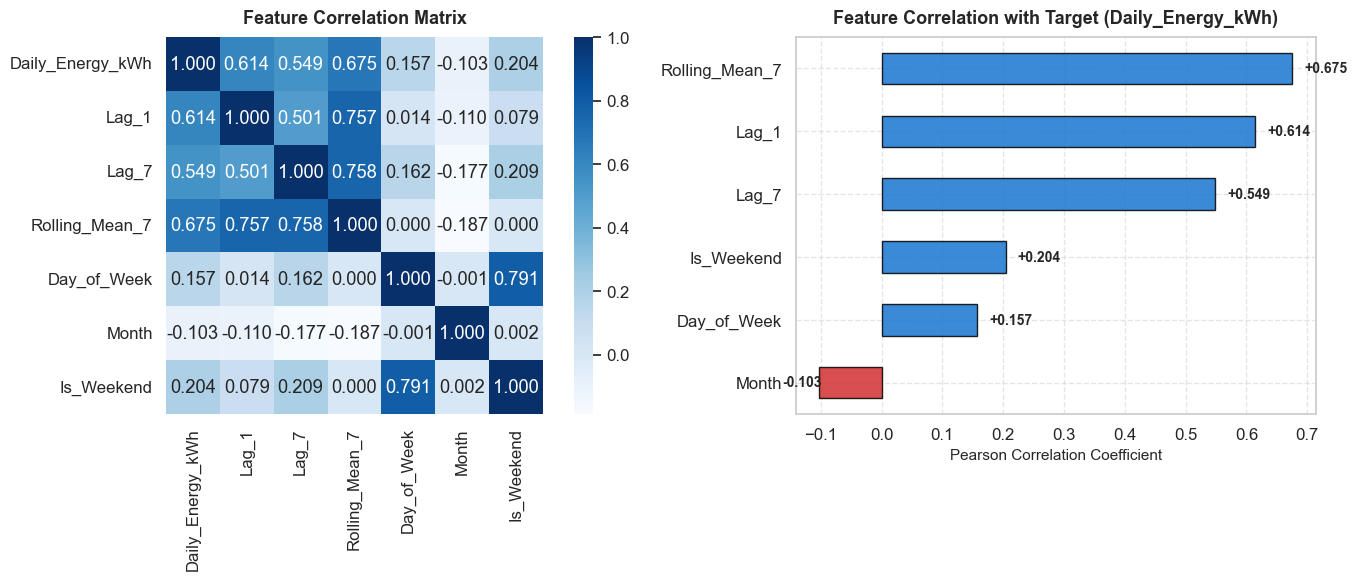

In [5]:
feature_cols = ['Lag_1', 'Lag_7', 'Rolling_Mean_7', 'Day_of_Week', 'Month', 'Is_Weekend']
corr_matrix = df_clean[['Daily_Energy_kWh'] + feature_cols].corr()

print("--- Pearson Correlation with Daily_Energy_kWh ---")
print(corr_matrix['Daily_Energy_kWh'].sort_values(ascending=False).to_string())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1.2, 1]})

# Heatmap
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='Blues', cbar=True, ax=ax1, square=True)
ax1.set_title('Feature Correlation Matrix', fontsize=13, fontweight='bold', pad=10)

# Bar chart of correlations with target
target_corrs = corr_matrix['Daily_Energy_kWh'].drop('Daily_Energy_kWh').sort_values(ascending=True)
colors = ['#d32f2f' if x < 0 else '#1976d2' for x in target_corrs.values]
target_corrs.plot(kind='barh', color=colors, ax=ax2, edgecolor='black', alpha=0.85)
ax2.set_title('Feature Correlation with Target (Daily_Energy_kWh)', fontsize=13, fontweight='bold', pad=10)
ax2.set_xlabel('Pearson Correlation Coefficient', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)

for i, v in enumerate(target_corrs.values):
    ax2.text(v + (0.02 if v >= 0 else -0.06), i, f"{v:+.3f}", va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


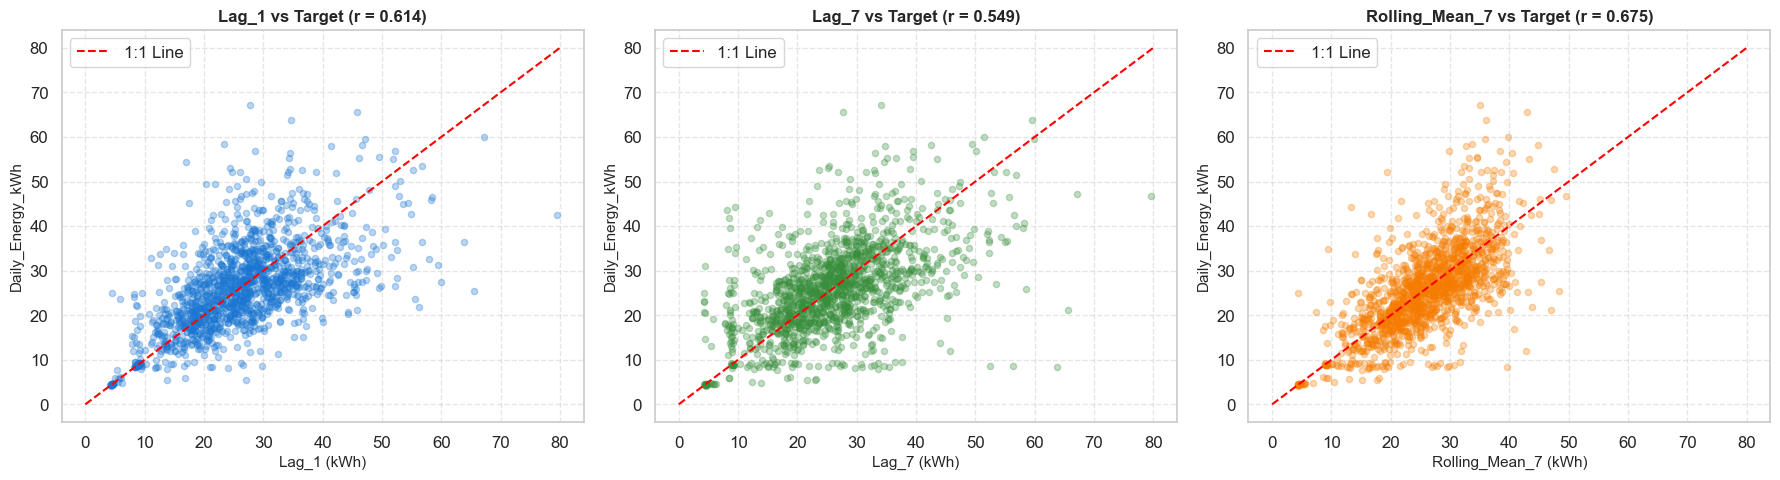

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Scatter Lag_1
axes[0].scatter(df_clean['Lag_1'], df_clean['Daily_Energy_kWh'], alpha=0.3, color='#1976d2', s=20)
axes[0].plot([0, 80], [0, 80], color='red', linestyle='--', label='1:1 Line')
axes[0].set_title(f"Lag_1 vs Target (r = {corr_matrix.loc['Lag_1', 'Daily_Energy_kWh']:.3f})", fontsize=12, fontweight='bold')
axes[0].set_xlabel('Lag_1 (kWh)', fontsize=11)
axes[0].set_ylabel('Daily_Energy_kWh', fontsize=11)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Scatter Lag_7
axes[1].scatter(df_clean['Lag_7'], df_clean['Daily_Energy_kWh'], alpha=0.3, color='#388e3c', s=20)
axes[1].plot([0, 80], [0, 80], color='red', linestyle='--', label='1:1 Line')
axes[1].set_title(f"Lag_7 vs Target (r = {corr_matrix.loc['Lag_7', 'Daily_Energy_kWh']:.3f})", fontsize=12, fontweight='bold')
axes[1].set_xlabel('Lag_7 (kWh)', fontsize=11)
axes[1].set_ylabel('Daily_Energy_kWh', fontsize=11)
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

# Scatter Rolling_Mean_7
axes[2].scatter(df_clean['Rolling_Mean_7'], df_clean['Daily_Energy_kWh'], alpha=0.3, color='#f57c00', s=20)
axes[2].plot([0, 80], [0, 80], color='red', linestyle='--', label='1:1 Line')
axes[2].set_title(f"Rolling_Mean_7 vs Target (r = {corr_matrix.loc['Rolling_Mean_7', 'Daily_Energy_kWh']:.3f})", fontsize=12, fontweight='bold')
axes[2].set_xlabel('Rolling_Mean_7 (kWh)', fontsize=11)
axes[2].set_ylabel('Daily_Energy_kWh', fontsize=11)
axes[2].legend()
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


## 6. Dataset Persistence and Validation
We save the final modeling dataset to `data/featured_daily_electricity_consumption.csv` and verify file integrity.


In [7]:
out_path = 'data/featured_daily_electricity_consumption.csv'
if not os.path.exists(os.path.dirname(out_path)):
    out_path = os.path.join('..', 'data', 'featured_daily_electricity_consumption.csv')

# Reorder columns: Date, Features, Target
ordered_cols = ['Date', 'Lag_1', 'Lag_7', 'Rolling_Mean_7', 'Day_of_Week', 'Month', 'Is_Weekend', 'Daily_Energy_kWh']
df_clean[ordered_cols].to_csv(out_path, index=False)

# Validate exported CSV
exp_df = pd.read_csv(out_path)
print(f"Exported dataset successfully to: {out_path}")
print(f"Total Rows:     {len(exp_df):,}")
print(f"Total Columns:  {len(exp_df.columns)}")
print(f"Column Names:   {list(exp_df.columns)}")
print(f"Missing Values: {exp_df.isnull().sum().to_dict()}")
print("\nFirst 5 Rows:")
print(exp_df.head(5).to_string())
print("\nLast 5 Rows:")
print(exp_df.tail(5).to_string())


Exported dataset successfully to: data/featured_daily_electricity_consumption.csv
Total Rows:     1,433
Total Columns:  8
Column Names:   ['Date', 'Lag_1', 'Lag_7', 'Rolling_Mean_7', 'Day_of_Week', 'Month', 'Is_Weekend', 'Daily_Energy_kWh']
Missing Values: {'Date': 0, 'Lag_1': 0, 'Lag_7': 0, 'Rolling_Mean_7': 0, 'Day_of_Week': 0, 'Month': 0, 'Is_Weekend': 0, 'Daily_Energy_kWh': 0}

First 5 Rows:
         Date   Lag_1   Lag_7  Rolling_Mean_7  Day_of_Week  Month  Is_Weekend  Daily_Energy_kWh
0  2006-12-24 79.5564 56.5077         43.6144            6     12           1           42.5002
1  2006-12-25 42.5002 36.7304         41.6134            0     12           0           45.7187
2  2006-12-26 45.7187 27.7699         42.8974            1     12           0           65.5685
3  2006-12-27 65.5685 37.0958         48.2972            2     12           0           25.4793
4  2006-12-28 25.4793 28.6186         46.6377            3     12           0           34.5440

Last 5 Rows:
           

## 7. Summary of Task 5 Outcomes
- **Features Created:** `Lag_1`, `Lag_7`, `Rolling_Mean_7`, `Day_of_Week`, `Month`, `Is_Weekend`.
- **Target Variable:** `Daily_Energy_kWh`.
- **Zero Target Leakage:** Verified via mathematical assertions; rolling averages strictly precede day $t$.
- **Boundary Handling:** Removed the initial 7 rows ($t=0$ to $t=6$), yielding 1,433 complete records (`2006-12-24` to `2010-11-25`).
- **Modular Library:** [`src/feature_engineering.py`](../src/feature_engineering.py) provides reproducible, parameterized feature pipelines.
- **Persistent Dataset:** [`data/featured_daily_electricity_consumption.csv`](../data/featured_daily_electricity_consumption.csv).
